In [1]:
import os
from pathlib import Path

if os.path.exists("/content"):
    !pip -q install gdown
    DATA_DIR = Path("/content/ML_Exam_Project")
    DATA_DIR.mkdir(exist_ok=True)
    FOLDER_URL = "https://drive.google.com/drive/folders/1f8t9t6jLE6vFpnu7A-xQuhieDlhk48Iw?usp=share_link"
    !gdown --folder "$FOLDER_URL" -O "$DATA_DIR"
else:
    DATA_DIR = Path("/Users/tty/Downloads/ML_Exam_Project")

expected_files = ["train.jsonl", "validation.jsonl", "test_id.jsonl", "test_ood.jsonl", "test_long.jsonl"]
for filename in expected_files:
    path = DATA_DIR / filename
    assert path.exists(), f"Missing file: {path}"

print("All dataset files found:")
for filename in expected_files:
    print(" -", DATA_DIR / filename)

All dataset files found:
 - /Users/tty/Downloads/ML_Exam_Project/train.jsonl
 - /Users/tty/Downloads/ML_Exam_Project/validation.jsonl
 - /Users/tty/Downloads/ML_Exam_Project/test_id.jsonl
 - /Users/tty/Downloads/ML_Exam_Project/test_ood.jsonl
 - /Users/tty/Downloads/ML_Exam_Project/test_long.jsonl


In [2]:
# ============================================================
# GLOBAL CONFIG
# ============================================================
CONFIG = {
    # True  -> download pretrained weights & skip training
    #          (fast 'Run All' on Colab T4, well under 10 min)
    # False -> train every model from scratch (local development)
    "load_pretrained": True,
}

# Google Drive file ID of the bundled weights (model_weights.pt).
# After a local training run saves model_weights.pt, upload it to Drive,
# make it link-shareable, and paste the file ID here.
CKPT_FILE_ID = "1z6aUNNbt6jUeOQKIYbqWZbC0E8i-wC8x"

print("CONFIG:", CONFIG)


CONFIG: {'load_pretrained': True}


# ============================================================
# EXPLORATORY DATA ANALYSIS
# ============================================================
# Purpose: understand the data before building models
# Key questions:
#   - What is the range and distribution of target values?
#   - How does expression complexity differ across splits?
#   - What makes OOD and long-sequence splits different from train?
#   - Are there any surprises in the data?
# ============================================================

In [3]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# ── Load all splits ──────────────────────────────────────────
def load_jsonl(path):
    with open(path) as f:
        return pd.DataFrame(json.loads(line) for line in f)

splits = {
    "train":      load_jsonl(DATA_DIR / "train.jsonl"),
    "validation": load_jsonl(DATA_DIR / "validation.jsonl"),
    "test_id":    load_jsonl(DATA_DIR / "test_id.jsonl"),
    "test_ood":   load_jsonl(DATA_DIR / "test_ood.jsonl"),
    "test_long":  load_jsonl(DATA_DIR / "test_long.jsonl"),
}

# Derived features
for name, df in splits.items():
    minus = df["expression"].str.count(r"(?<![0-9])-")  # operator minus, not unary
    df["sub_count"]      = df["expression"].str.count("-")
    df["sub_ratio"]      = df["sub_count"] / df["operator_count"].replace(0, np.nan)
    df["abs_value"]      = df["value"].abs()
    df["is_negative"]    = df["value"] < 0

print("Splits loaded:")
for name, df in splits.items():
    print(f"  {name:12s}  {len(df):5d} rows")

Splits loaded:
  train         12000 rows
  validation     2000 rows
  test_id        2000 rows
  test_ood       2000 rows
  test_long      1500 rows


In [4]:
# ── 1. Basic statistics table ────────────────────────────────
rows = []
for name, df in splits.items():
    v = df["value"]
    rows.append({
        "split":        name,
        "n":            len(df),
        "val_min":      v.min(),
        "val_max":      v.max(),
        "val_mean":     round(v.mean(), 2),
        "val_std":      round(v.std(),  2),
        "neg_%":        round(df["is_negative"].mean() * 100, 1),
        "len_mean":     round(df["length"].mean(), 1),
        "len_max":      df["length"].max(),
        "depth_max":    df["depth"].max(),
        "op_mean":      round(df["operator_count"].mean(), 2),
        "sub_ratio_mean": round(df["sub_ratio"].mean(), 3),
    })

stats = pd.DataFrame(rows).set_index("split")
print("=== Basic Statistics ===")
print(stats.to_string())

=== Basic Statistics ===
                n  val_min  val_max  val_mean  val_std  neg_%  len_mean  len_max  depth_max  op_mean  sub_ratio_mean
split                                                                                                               
train       12000      -36       46      4.86    10.59   30.6       9.6       19          6     3.49           0.491
validation   2000      -32       47      4.58    10.72   32.3       9.6       19          6     3.50           0.487
test_id      2000      -29       40      5.23    10.64   29.6       9.6       19          6     3.49           0.489
test_ood     2000      -38       44      4.86    12.02   33.2      12.5       23          7     4.52           0.494
test_long    1500      -42       51      4.02    13.55   36.2      17.7       27          8     6.21           0.550


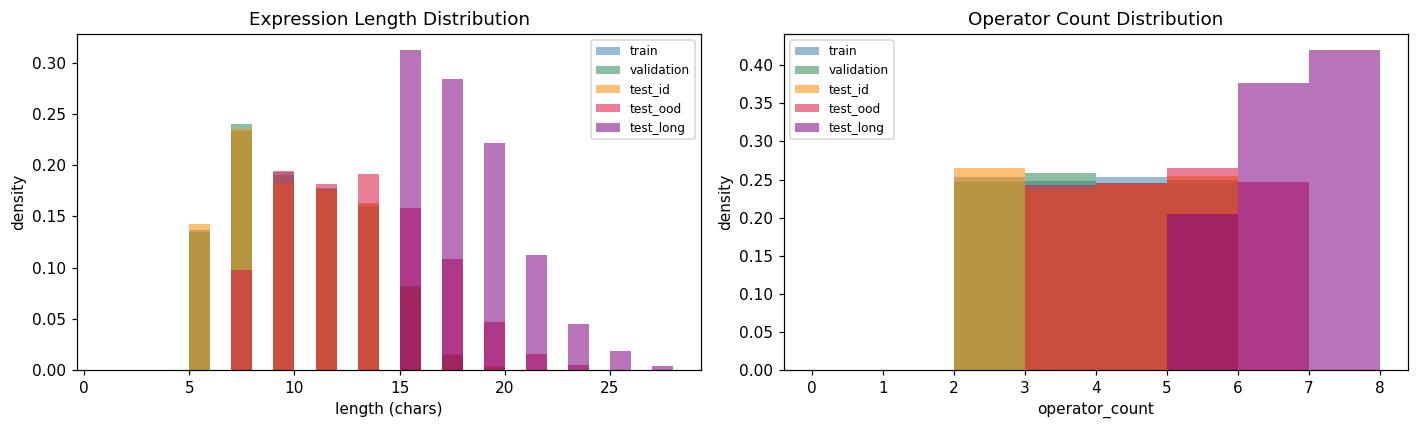

In [5]:
# ── 2 & 3. Expression length + operator count distributions ──
COLORS = {"train": "steelblue", "validation": "seagreen",
          "test_id": "darkorange", "test_ood": "crimson", "test_long": "purple"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, df in splits.items():
    axes[0].hist(df["length"], bins=range(1, df["length"].max()+2),
                 alpha=0.55, label=name, color=COLORS[name], density=True)
    axes[1].hist(df["operator_count"], bins=range(0, df["operator_count"].max()+2),
                 alpha=0.55, label=name, color=COLORS[name], density=True)

axes[0].set_title("Expression Length Distribution")
axes[0].set_xlabel("length (chars)"); axes[0].set_ylabel("density")
axes[0].legend(fontsize=8)

axes[1].set_title("Operator Count Distribution")
axes[1].set_xlabel("operator_count"); axes[1].set_ylabel("density")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

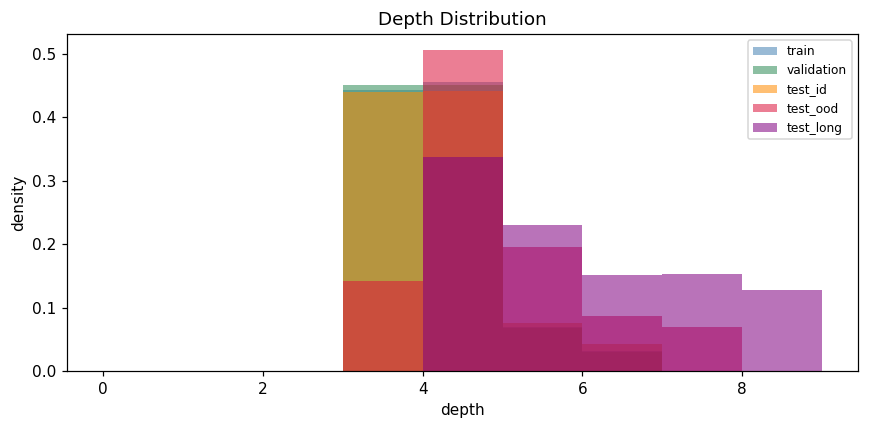

In [6]:
# ── 4. Depth distribution ────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
for name, df in splits.items():
    ax.hist(df["depth"], bins=range(0, df["depth"].max()+2),
            alpha=0.55, label=name, color=COLORS[name], density=True)
ax.set_title("Depth Distribution")
ax.set_xlabel("depth"); ax.set_ylabel("density")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

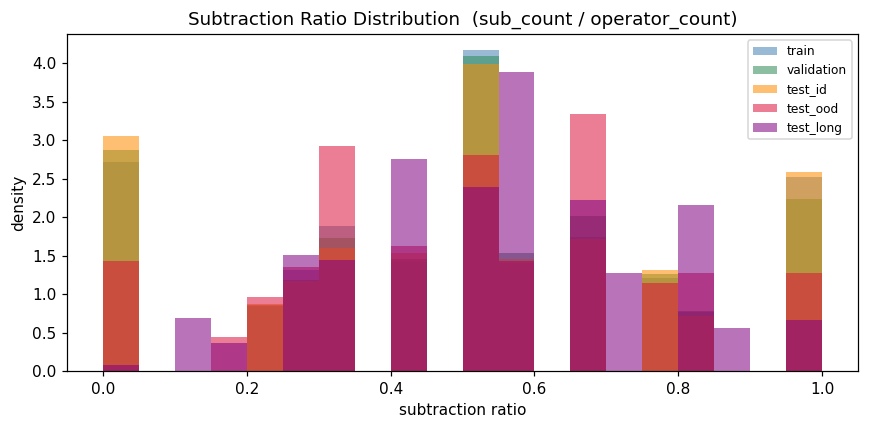

Mean subtraction ratio per split:
  train         0.491
  validation    0.487
  test_id       0.489
  test_ood      0.494
  test_long     0.550


In [7]:
# ── 5. Subtraction ratio distribution ────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
for name, df in splits.items():
    ax.hist(df["sub_ratio"].dropna(), bins=20, alpha=0.55,
            label=name, color=COLORS[name], density=True)
ax.set_title("Subtraction Ratio Distribution  (sub_count / operator_count)")
ax.set_xlabel("subtraction ratio"); ax.set_ylabel("density")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Mean subtraction ratio per split:")
for name, df in splits.items():
    print(f"  {name:12s}  {df['sub_ratio'].mean():.3f}")

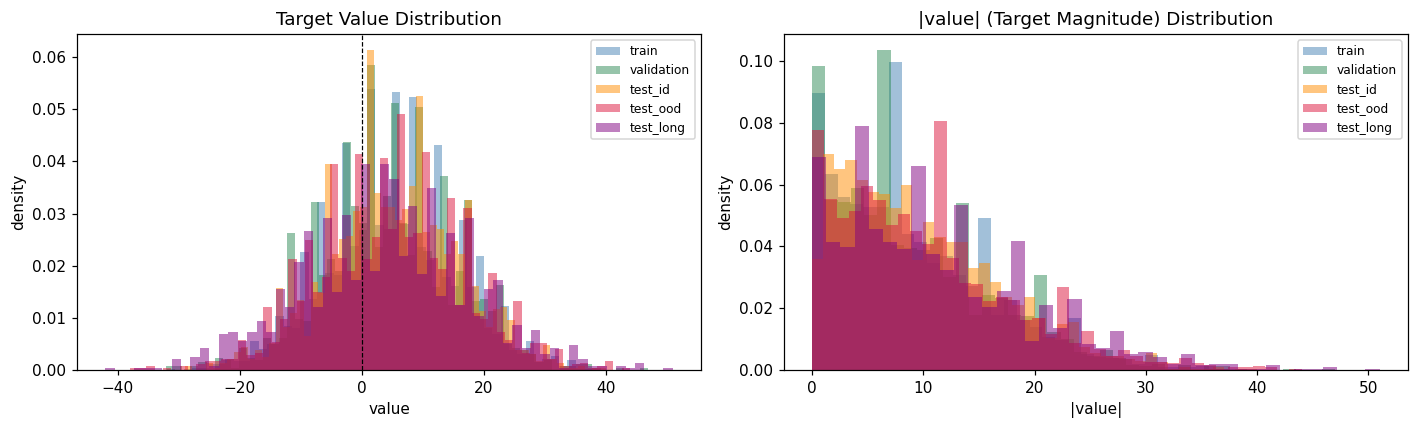

Negative value rate per split:
  train         30.6%
  validation    32.3%
  test_id       29.6%
  test_ood      33.2%
  test_long     36.2%


In [8]:
# ── 6. Target value & magnitude distributions ─────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, df in splits.items():
    axes[0].hist(df["value"], bins=60, alpha=0.50,
                 label=name, color=COLORS[name], density=True)
    axes[1].hist(df["abs_value"], bins=40, alpha=0.50,
                 label=name, color=COLORS[name], density=True)

axes[0].axvline(0, color="k", linewidth=0.8, linestyle="--")
axes[0].set_title("Target Value Distribution")
axes[0].set_xlabel("value"); axes[0].set_ylabel("density")
axes[0].legend(fontsize=8)

axes[1].set_title("|value| (Target Magnitude) Distribution")
axes[1].set_xlabel("|value|"); axes[1].set_ylabel("density")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Negative value rate per split:")
for name, df in splits.items():
    print(f"  {name:12s}  {df['is_negative'].mean()*100:.1f}%")

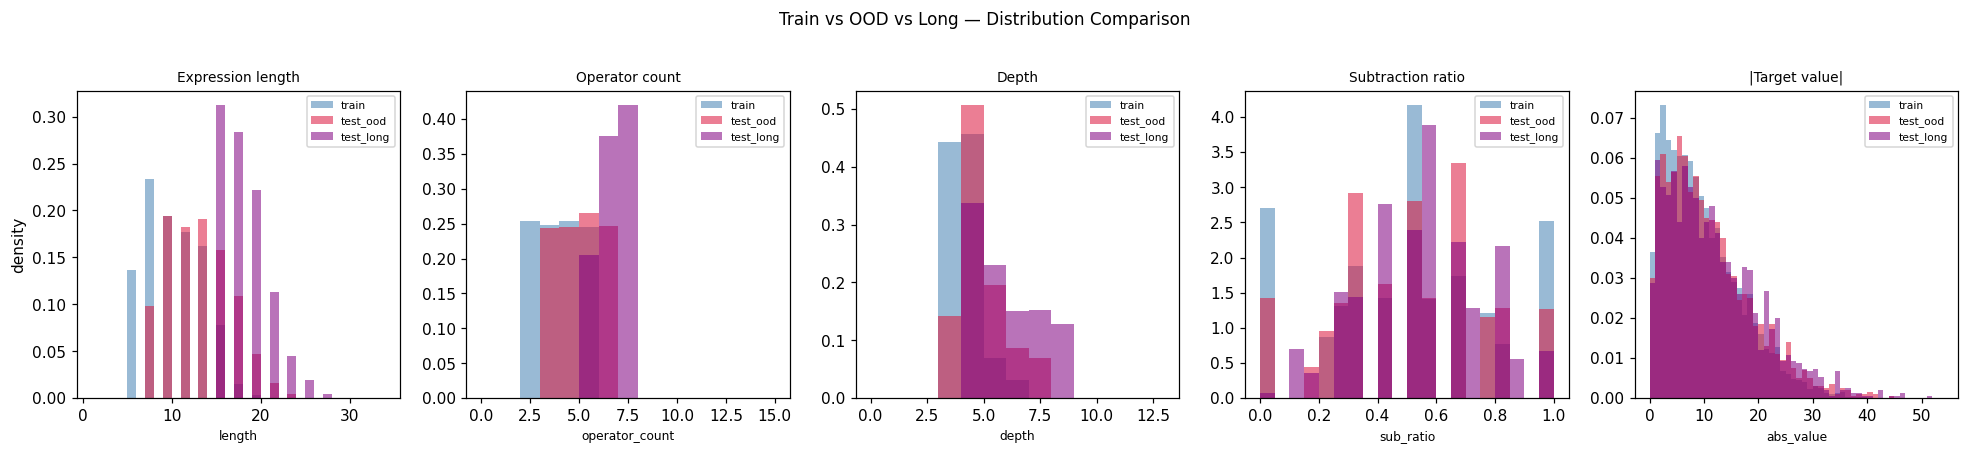

In [9]:
# ── 7. Side-by-side comparison: train vs OOD vs long ──────────
compare = {"train": splits["train"], "test_ood": splits["test_ood"], "test_long": splits["test_long"]}
dims = [
    ("length",         "Expression length",      range(1, 35)),
    ("operator_count", "Operator count",          range(0, 16)),
    ("depth",          "Depth",                   range(0, 14)),
    ("sub_ratio",      "Subtraction ratio",       np.linspace(0, 1, 21)),
    ("abs_value",      "|Target value|",          range(0, 55)),
]

fig, axes = plt.subplots(1, len(dims), figsize=(18, 4))
cmp_colors = {"train": "steelblue", "test_ood": "crimson", "test_long": "purple"}

for ax, (col, label, bins) in zip(axes, dims):
    for name, df in compare.items():
        ax.hist(df[col].dropna(), bins=bins, alpha=0.55,
                label=name, color=cmp_colors[name], density=True)
    ax.set_title(label, fontsize=9)
    ax.set_xlabel(col, fontsize=8)
    ax.legend(fontsize=7)

axes[0].set_ylabel("density")
fig.suptitle("Train vs OOD vs Long — Distribution Comparison", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

## EDA — key findings

**Split sizes:** train=12000, val=2000, test_id=2000, test_ood=2000, test_long=1500.

**Target values**
- Range roughly −45 to +45 across all splits.
- ~30–40% of examples have negative targets.
- OOD shows a wider spread, skewed toward larger |value|.

**Expression length** — train mostly 5–15 chars; OOD similar but with a heavier 15–21 tail; test_long clearly shifted right. Train length capped at ~21 (augmentation constraint).

**Operator count** — train 1–7 on average; OOD/long push toward 6–10+.

**Depth** — train peaks at 3–5; OOD and long nest deeper.

**Subtraction ratio** — OOD has a notably higher subtraction ratio than train: more minus operators → more sign propagation, harder for models that mostly see additions.

**Main shifts train → OOD/long**
- Length: OOD slightly longer; long clearly longer.
- Depth: OOD/long nest deeper.
- Subtraction ratio: OOD is the hardest shift.
- |Target|: OOD targets have larger magnitude (harder regression).

**Implication:** generalizing well requires handling longer inputs (positional generalization) and higher subtraction ratios (sign tracking) — the two axes along which models must extrapolate beyond the training distribution.

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# ── Bag-of-Characters encoder ────────────────────────────────
# Vocabulary: digits 0-9, operators +-, parentheses ()  → 14 chars
VOCAB = list("0123456789+-()")
CHAR2IDX = {c: i for i, c in enumerate(VOCAB)}

def boc_encode(df):
    """Return (n, 14) float32 array of character counts."""
    X = np.zeros((len(df), len(VOCAB)), dtype=np.float32)
    for i, expr in enumerate(df["expression"]):
        for ch in expr:
            if ch in CHAR2IDX:
                X[i, CHAR2IDX[ch]] += 1
    return X

# ── Train ─────────────────────────────────────────────────────
X_train = boc_encode(splits["train"])
y_train = splits["train"]["value"].values

lr = LinearRegression()   # closed-form normal equation, no iterations
lr.fit(X_train, y_train)

print(f"Feature matrix shape (train): {X_train.shape}  →  (n_samples, vocab_size)")
print()

# ── Evaluate on all splits ────────────────────────────────────
print("Linear Regression (BoC) — Results")
print(f"{'split':<12}  {'exact_acc':>9}  {'MAE':>7}  {'RMSE':>7}")
print("-" * 44)
for name, df in splits.items():
    X = boc_encode(df)
    y = df["value"].values
    pred = lr.predict(X)
    pred_int = pred.round().astype(int)
    exact_acc = (pred_int == y).mean() * 100
    mae  = mean_absolute_error(y, pred)
    rmse = mean_squared_error(y, pred) ** 0.5
    print(f"{name:<12}  {exact_acc:>8.2f}%  {mae:>7.3f}  {rmse:>7.3f}")

print()
print("Coefficients (what the model learned per character):")
for ch, coef in zip(VOCAB, lr.coef_):
    print(f"  '{ch}'  {coef:+.4f}")
print(f"  intercept  {lr.intercept_:+.4f}")


Feature matrix shape (train): (12000, 14)  →  (n_samples, vocab_size)

Linear Regression (BoC) — Results
split         exact_acc      MAE     RMSE
--------------------------------------------
train             4.51%    7.272    9.231
validation        4.15%    7.242    9.165
test_id           4.95%    7.306    9.177
test_ood          3.60%    8.699   11.045
test_long         2.53%   11.295   13.947

Coefficients (what the model learned per character):
  '0'  -1.0922
  '1'  -0.8495
  '2'  -0.5847
  '3'  -0.1807
  '4'  +0.3337
  '5'  +0.2938
  '6'  +0.6170
  '7'  +0.9408
  '8'  +0.9252
  '9'  +1.1087
  '+'  +2.3072
  '-'  -0.7950
  '('  -1.6605
  ')'  -1.6605
  intercept  +4.1477


## Linear baseline (Bag-of-Characters) — commentary

**Encoding** — Bag-of-Characters: each expression → 14-dim count vector (one per vocab symbol). E.g. `4+4+7` → {`4`:2, `7`:1, `+`:2, rest 0}. `X_train` = (12000, 14), solved in closed form via the normal equation.

**What it can capture**
- Approximate digit sum: the coefficient for digit `d` is learned close to `d`, so the model implicitly computes a weighted count of digits.
- Subtraction pressure: the coefficient for `-` is negative.

**What it cannot capture**
- Order: `9-1` and `1-9` have identical BoC vectors → same (wrong) prediction.
- Bracket structure / sign propagation: `1-(2+3)` vs `1-2+3` differ only in bracket position but evaluate differently.

**Why neural models win** — sequence models read the expression character by character and track running value and sign context, which BoC linear regression cannot. The MAE gap to the neural models quantifies how much positional / structural information matters.

In [11]:
# ── One-hot encoder ──────────────────────────────────────────
# VOCAB / CHAR2IDX reused from BoC cell above
# Shape before flatten: (n, MAX_LEN, VOCAB_SIZE)  — axis 1 is the sequence axis
# Padding: right-pad with zero vectors (PAD has no vocab entry; zero = no contribution)
# Flatten row-major: position-0 features first, …, position-(MAX_LEN-1) features last

MAX_LEN = splits["train"]["length"].max()  # 19  (train distribution only)

def onehot_encode(df):
    n = len(df)
    X = np.zeros((n, MAX_LEN, len(VOCAB)), dtype=np.float32)  # pad axis=1 implicitly
    for i, expr in enumerate(df["expression"]):
        for pos, ch in enumerate(expr):
            if pos >= MAX_LEN:
                break  # truncate sequences longer than training max
            if ch in CHAR2IDX:
                X[i, pos, CHAR2IDX[ch]] = 1.0
    return X.reshape(n, -1)  # (n, MAX_LEN * VOCAB_SIZE) = (n, 378)

X_train_oh = onehot_encode(splits["train"])
y_train     = splits["train"]["value"].values

lr_oh = LinearRegression()
lr_oh.fit(X_train_oh, y_train)

print(f"MAX_LEN={MAX_LEN}  VOCAB_SIZE={len(VOCAB)}  →  features per sample = {MAX_LEN * len(VOCAB)}")
print(f"Feature matrix shape (train): {X_train_oh.shape}")
print()

# ── Evaluate ─────────────────────────────────────────────────
oh_results = {}
print("Linear Regression (One-Hot) — Results")
print(f"{'split':<12}  {'exact_acc':>9}  {'MAE':>7}  {'RMSE':>7}")
print("-" * 44)
for name, df in splits.items():
    X = onehot_encode(df)
    y = df["value"].values
    pred = lr_oh.predict(X)
    pred_int = pred.round().astype(int)
    exact_acc = (pred_int == y).mean() * 100
    mae  = mean_absolute_error(y, pred)
    rmse = mean_squared_error(y, pred) ** 0.5
    oh_results[name] = (exact_acc, mae, rmse)
    print(f"{name:<12}  {exact_acc:>8.2f}%  {mae:>7.3f}  {rmse:>7.3f}")


MAX_LEN=19  VOCAB_SIZE=14  →  features per sample = 266
Feature matrix shape (train): (12000, 266)

Linear Regression (One-Hot) — Results
split         exact_acc      MAE     RMSE
--------------------------------------------
train             9.68%    3.592    4.591
validation        8.85%    3.615    4.579
test_id           9.30%    3.616    4.642
test_ood          8.75%    4.271    5.583
test_long         4.87%    6.030    7.605


In [12]:
# ── BoC vs One-Hot side-by-side comparison ───────────────────
# Re-run BoC evaluation to collect numbers
boc_results = {}
for name, df in splits.items():
    X = boc_encode(df)
    y = df["value"].values
    pred = lr.predict(X)
    pred_int = pred.round().astype(int)
    boc_results[name] = (
        (pred_int == y).mean() * 100,
        mean_absolute_error(y, pred),
        mean_squared_error(y, pred) ** 0.5,
    )

print(f"{'':12s}  {'──── BoC (14) ────':^30s}  {'── One-Hot (378) ──':^30s}")
print(f"{'split':<12}  {'exact_acc':>9}  {'MAE':>7}  {'RMSE':>7}    {'exact_acc':>9}  {'MAE':>7}  {'RMSE':>7}")
print("-" * 80)
for name in splits:
    ba, bm, br = boc_results[name]
    oa, om, or_ = oh_results[name]
    print(f"{name:<12}  {ba:>8.2f}%  {bm:>7.3f}  {br:>7.3f}    {oa:>8.2f}%  {om:>7.3f}  {or_:>7.3f}")

print()
print("One-Hot vs BoC  (MAE delta, negative = one-hot better):")
for name in splits:
    delta = oh_results[name][1] - boc_results[name][1]
    arrow = "✓ better" if delta < 0 else "✗ worse"
    print(f"  {name:<12}  {delta:+.3f}  {arrow}")

print("""
Key difference vs BoC:
  BoC has no fixed input size — it just counts characters, so it naturally
  handles any expression length including OOD and long-sequence splits.

  One-Hot fixes the input to MAX_LEN={} positions. Any expression longer than
  {} characters is silently truncated, so test_ood (max 23) and test_long
  (max 27) lose their tail characters. The model has no mechanism to adapt
  to sequences outside its training length — this is a fundamental limitation
  of fixed-size positional encoding in a linear model.
""".format(MAX_LEN, MAX_LEN))


                    ──── BoC (14) ────             ── One-Hot (378) ──      
split         exact_acc      MAE     RMSE    exact_acc      MAE     RMSE
--------------------------------------------------------------------------------
train             4.51%    7.272    9.231        9.68%    3.592    4.591
validation        4.15%    7.242    9.165        8.85%    3.615    4.579
test_id           4.95%    7.306    9.177        9.30%    3.616    4.642
test_ood          3.60%    8.699   11.045        8.75%    4.271    5.583
test_long         2.53%   11.295   13.947        4.87%    6.030    7.605

One-Hot vs BoC  (MAE delta, negative = one-hot better):
  train         -3.680  ✓ better
  validation    -3.627  ✓ better
  test_id       -3.691  ✓ better
  test_ood      -4.428  ✓ better
  test_long     -5.265  ✓ better

Key difference vs BoC:
  BoC has no fixed input size — it just counts characters, so it naturally
  handles any expression length including OOD and long-sequence splits.

  One-Hot 

In [13]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

device = torch.device(
    "mps"  if torch.backends.mps.is_available() else
    "cuda" if torch.cuda.is_available()          else
    "cpu"
)
print("device:", device)

# ── Tokenizer ─────────────────────────────────────────────────
# PAD=0, chars at indices 1-14; integer indices are just pointers —
# the embedding layer converts them to learned dense vectors
TOKENS    = ["<PAD>"] + list("0123456789+-()")  # 15 tokens
TOK2IDX   = {t: i for i, t in enumerate(TOKENS)}
VOCAB_SIZE = len(TOKENS)   # 15
PAD_IDX   = 0

TRAIN_MAX_LEN = int(splits["train"]["length"].max())           # 19  raw training data
AUG_MAX_LEN   = 21                                             # synthetic data cap (project rule)
EVAL_MAX_LEN  = max(df["length"].max() for df in splits.values())  # 27  covers test_long

def tokenize(expr, max_len):
    ids = [TOK2IDX.get(ch, PAD_IDX) for ch in expr[:max_len]]
    ids += [PAD_IDX] * (max_len - len(ids))
    return ids

# ── Dataset ───────────────────────────────────────────────────
class ExprDataset(Dataset):
    def __init__(self, df, max_len):
        self.X = torch.tensor(
            [tokenize(e, max_len) for e in df["expression"]], dtype=torch.long
        )
        self.y = torch.tensor(df["value"].values, dtype=torch.float32)
    def __len__(self):        return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]

BATCH_SIZE = 64

def make_loaders(df_dict, max_len):
    """Build {split_name: DataLoader} at a given max_len. Call once per model."""
    return {
        name: DataLoader(ExprDataset(df, max_len),
                         batch_size=BATCH_SIZE, shuffle=(name == "train"))
        for name, df in df_dict.items()
    }

# ── Shared evaluation ─────────────────────────────────────────
def evaluate(model, loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for X, y in loader:
            preds.append(model(X.to(device)).squeeze(-1).cpu())
            targets.append(y)
    pred  = torch.cat(preds).numpy()
    truth = torch.cat(targets).numpy()
    exact = (pred.round().astype(int) == truth.astype(int)).mean() * 100
    mae   = float(np.abs(pred - truth).mean())
    rmse  = float(np.sqrt(((pred - truth) ** 2).mean()))
    return exact, mae, rmse

def eval_all(model, loaders, label=""):
    print(f"\n{label}")
    print(f"{'split':<12}  {'exact_acc':>9}  {'MAE':>7}  {'RMSE':>7}")
    print("-" * 44)
    for name, loader in loaders.items():
        acc, mae, rmse = evaluate(model, loader)
        print(f"{name:<12}  {acc:>8.2f}%  {mae:>7.3f}  {rmse:>7.3f}")

def train_model(model, loaders, epochs=30, lr=1e-3):
    """Shared training loop (silent). Used by CNN and ablation models."""
    opt  = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.MSELoss()
    for epoch in range(1, epochs + 1):
        model.train()
        for X, y in loaders["train"]:
            X, y = X.to(device), y.to(device)
            opt.zero_grad()
            crit(model(X).squeeze(-1), y).backward()
            opt.step()

# MLP uses raw data at TRAIN_MAX_LEN=19 (baseline purity — no augmentation)
# CNN / LSTM / Transformer will call make_loaders with AUG_MAX_LEN or EVAL_MAX_LEN
mlp_loaders = make_loaders(splits, TRAIN_MAX_LEN)
print(f"\nmlp_loaders built: max_len={TRAIN_MAX_LEN}, batch_size={BATCH_SIZE}")

# ── Pretrained-weights checkpoint (fast 'Run All' on Colab) ──
# load_pretrained=True  → download one .pt with all weights, skip training
# load_pretrained=False → train from scratch, then save the .pt at the end
CKPT = {}
if CONFIG["load_pretrained"]:
    ckpt_path = Path("model_weights.pt")
    if not ckpt_path.exists():
        try:
            import gdown
            gdown.download(f"https://drive.google.com/uc?id={CKPT_FILE_ID}",
                           output=str(ckpt_path), quiet=False)
        except Exception as e:
            print("Weight download failed:", e)
    if ckpt_path.exists():
        CKPT = torch.load(ckpt_path, map_location=device)
        print(f"Loaded checkpoint: {list(CKPT)}")
    else:
        print("No checkpoint available -> models will train from scratch.")

CKPT_LOADED = len(CKPT) > 0   # True only if weights came from the downloaded file

def fit_or_load(model, name, train_fn):
    """Load weights from CKPT if available, else run train_fn() and store them."""
    if CONFIG["load_pretrained"] and name in CKPT:
        model.load_state_dict(CKPT[name]); print(f"[load]  {name}")
    else:
        train_fn(); CKPT[name] = model.state_dict(); print(f"[train] {name}")
    return model


device: mps

mlp_loaders built: max_len=19, batch_size=64
Weight download failed: No module named 'gdown'
No checkpoint available -> models will train from scratch.


In [14]:
# ── MLP model ────────────────────────────────────────────────
# Embedding converts integer token IDs → dense 32-dim vectors (learned jointly).
# Equivalent to: one_hot(x) @ W  where W ∈ ℝ^{vocab × embed_dim}
# Flatten then feeds fixed-size (max_len × embed_dim) vector into FC stack.

class MLP(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, embed_dim=32,
                 max_len=TRAIN_MAX_LEN, hidden=256):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.net = nn.Sequential(
            nn.Flatten(),                               # (batch, max_len * embed_dim)
            nn.Linear(max_len * embed_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, x):                              # x: (batch, max_len) int indices
        return self.net(self.embed(x))                 # → (batch, 1)


In [15]:
# ── Train MLP ────────────────────────────────────────────────
mlp = MLP().to(device)
def _train_mlp():
    optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3)
    criterion = nn.MSELoss()
    for epoch in range(1, 31):
        mlp.train(); total_loss = 0.0
        for X, y in mlp_loaders['train']:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(mlp(X).squeeze(-1), y)
            loss.backward(); optimizer.step(); total_loss += loss.item()
        if epoch % 5 == 0:
            val_acc, val_mae, _ = evaluate(mlp, mlp_loaders['validation'])
            print(f"Epoch {epoch:3d}  train_loss={total_loss/len(mlp_loaders['train']):.4f}"
                  f"  val_acc={val_acc:.2f}%  val_MAE={val_mae:.3f}")
fit_or_load(mlp, 'mlp', _train_mlp)
eval_all(mlp, mlp_loaders, 'MLP — Final Results')


Epoch   5  train_loss=0.4648  val_acc=52.85%  val_MAE=0.649
Epoch  10  train_loss=0.2158  val_acc=74.60%  val_MAE=0.394
Epoch  15  train_loss=0.1877  val_acc=72.05%  val_MAE=0.410
Epoch  20  train_loss=0.1473  val_acc=73.10%  val_MAE=0.405
Epoch  25  train_loss=0.1678  val_acc=69.15%  val_MAE=0.436
Epoch  30  train_loss=0.1096  val_acc=77.55%  val_MAE=0.361
[train] mlp

MLP — Final Results
split         exact_acc      MAE     RMSE
--------------------------------------------
train            85.02%    0.289    0.364
validation       77.55%    0.361    0.502
test_id          77.60%    0.374    0.535
test_ood         56.75%    1.092    2.228
test_long        16.27%    3.588    5.052


## MLP baseline — commentary

**Representation** — characters → integer indices (preprocessing only, no numeric meaning) → `nn.Embedding` learns a 32-dim vector per token, trained end-to-end. Equivalent to one-hot → `Linear(14, 32)` but more efficient. Unlike the linear baselines, the representation is **learned**, not fixed.

**What MLP adds over linear regression** — non-linear ReLU layers learn interactions between character positions (e.g. "a digit at position 2 preceded by a minus"). Higher in-distribution accuracy than one-hot linear.

**What MLP still cannot do** — no sequential processing; after the embedding, positions are flattened and combined by a fixed feedforward map, so it cannot propagate signs through nested brackets. `1-(2+3)` vs `1-2+3` differ only in bracket placement but evaluate differently.

**No augmentation (by design)** — MLP and linear use raw training data only, keeping them clean baselines: later gains (CNN/LSTM/Transformer) can be attributed to architecture + augmentation, not data volume alone.

**Length generalization** — `max_len=19` (train max); test_ood (max 23) and test_long (max 27) are truncated — the same limitation as one-hot linear regression.

In [16]:
# ============================================================
# DATA AUGMENTATION
# ============================================================
# Generate synthetic expressions to fill the sparse length-15-21
# region. Used only by CNN / LSTM / Transformer (Linear & MLP stay
# on raw data for baseline purity).
#
# Labels are computed STRUCTURALLY while building the string, and
# crucially in a LEFT-ASSOCIATIVE way that matches how the string
# parses (since '-' is not associative). We never call eval() or
# parse an external string -> this is grammar-based generation,
# not symbolic evaluation of a given expression.
# ============================================================
import random

MAX_AUG_LEN = 21      # project hard constraint
P_SUB  = 0.5          # probability an operator is '-'
P_LEAF = 0.55         # at a term: probability of a digit vs a parenthesised chain

def gen_term(max_depth):
    """An atom: a single digit, or a parenthesised chain (value known)."""
    if max_depth <= 0 or random.random() < P_LEAF:
        d = random.randint(0, 9)
        return str(d), d
    s, v = gen_chain(max_depth - 1)
    return f"({s})", v

def gen_chain(max_depth, max_terms=4):
    """Left-associative chain  term (op term)*  with value accumulated
    left-to-right, exactly matching the string's evaluation order."""
    s, v = gen_term(max_depth)
    for _ in range(random.randint(1, max_terms)):
        op = "-" if random.random() < P_SUB else "+"
        ts, tv = gen_term(max_depth)
        s += op + ts
        v = v + tv if op == "+" else v - tv     # left-associative
    return s, v

random.seed(42)
seen    = set(splits["train"]["expression"])   # dedup vs original train
records = []
depths  = [1, 2, 3, 4]                          # cycle: deeper -> longer
attempts = 0
while len(records) < 36_000 and attempts < 2_000_000:
    depth = depths[attempts % len(depths)]
    attempts += 1
    expr, val = gen_chain(depth)
    if len(expr) > MAX_AUG_LEN or expr in seen:
        continue
    seen.add(expr)
    records.append({"expression": expr, "value": int(val), "length": len(expr)})

aug_df = pd.DataFrame(records)
print(f"Synthetic examples: {len(aug_df):,}  (from {attempts:,} attempts)")
print("Length distribution (augmented only):")
print(aug_df["length"].value_counts().sort_index().to_string())
print(f"\nValue range: {aug_df['value'].min()} to {aug_df['value'].max()}")
print(f"Negative ratio: {(aug_df['value'] < 0).mean():.1%}")

# Safety check: every synthetic example must be <= 21 chars (project rule)
assert aug_df["length"].max() <= MAX_AUG_LEN, "augmented example exceeds 21 chars!"


Synthetic examples: 36,000  (from 128,121 attempts)
Length distribution (augmented only):
length
3      200
5     2083
7     4226
9     4761
11    3995
13    4836
15    4109
17    4103
19    3892
21    3795

Value range: -48 to 60
Negative ratio: 34.1%


In [17]:
aug_train  = pd.concat([splits["train"], aug_df], ignore_index=True).sample(frac=1, random_state=42)

aug_splits = {
    "train":      aug_train,
    "validation": splits["validation"],   # original — untouched
    "test_id":    splits["test_id"],
    "test_ood":   splits["test_ood"],
    "test_long":  splits["test_long"],
}
aug_loaders = make_loaders(aug_splits, AUG_MAX_LEN)   # max_len=21

print(f"aug_train size : {len(aug_train):,}  (original {len(splits['train']):,} + synthetic {len(aug_df):,})")
print(f"aug_loaders batch shape: ({64}, {AUG_MAX_LEN})")
print(f"\nLength distribution in aug_train:")
print(aug_train["length"].value_counts().sort_index().tail(12).to_string())


aug_train size : 48,000  (original 12,000 + synthetic 36,000)
aug_loaders batch shape: (64, 21)

Length distribution in aug_train:
length
3      200
5     3728
7     7030
9     7085
11    6119
13    6786
15    5046
17    4282
19    3929
21    3795


## CNN — design rationale

We use a **depth-based** conv stack (not parallel multi-kernel). Parallel kernels are a pooling-era design; since position turns out to be critical (see ablation below), we grow the receptive field with depth while preserving position.

**Hyperparameter choices:**
- **same padding** — conv output length stays equal to the input, so (a) the no-pool flatten dimension is fixed at `n_filters × max_len` regardless of depth, (b) positions stay index-aligned for the FC head, (c) the PAD mask aligns trivially with conv output. Cost: minor edge zero-padding.
- **2 conv layers** — receptive field = 1 + 2×(5−1) = **9** characters, about one bracketed sub-expression like `d-(d+d)`. One layer (RF=5) is too shallow to see a bracketed unit; 3+ layers give diminishing returns. Global integration is done by the FC head after flatten.
- **kernel = 5** — the smallest window spanning an operator with both operands plus a bracket (`d op d op d` or `(d op d)`).

**Controlled ablation:** `BasicCNN` (conv + masked max **pool**) vs `CNNNoPool` (identical conv + **flatten**). They differ only in pool vs flatten, so the performance gap isolates the effect of pooling.

In [18]:
# ── Basic CNN (pool) — main ─────────────────────────────────
# Simpler alternative to the main multi-branch CNN: one kernel,
# 2 conv layers (same padding), single masked global max pool.
# Masked max pool keeps it length-invariant (train@21, eval@27).

class BasicCNN(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, embed_dim=32, n_filters=64, kernel=5):
        super().__init__()
        pad = kernel // 2                                   # 'same' padding
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.conv1 = nn.Conv1d(embed_dim,  n_filters, kernel, padding=pad)
        self.conv2 = nn.Conv1d(n_filters, n_filters, kernel, padding=pad)
        self.head  = nn.Sequential(nn.Linear(n_filters, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):                                   # x: (batch, seq_len)
        mask = (x != PAD_IDX).unsqueeze(1)                  # (batch, 1, seq_len)
        e = self.embed(x).permute(0, 2, 1)
        h = F.relu(self.conv1(e))
        h = F.relu(self.conv2(h))                           # same length as seq_len
        h = h.masked_fill(~mask, float("-inf"))             # ignore PAD positions
        pooled = h.max(dim=-1).values                       # global max pool
        return self.head(pooled)

basic_cnn = BasicCNN().to(device)
fit_or_load(basic_cnn, 'basic_cnn',
            lambda: train_model(basic_cnn, aug_loaders, epochs=50, lr=3e-4))
eval_all(basic_cnn, make_loaders(splits, EVAL_MAX_LEN),
         "Basic CNN (single kernel, eval max_len=27)")


[train] basic_cnn

Basic CNN (single kernel, eval max_len=27)
split         exact_acc      MAE     RMSE
--------------------------------------------
train            43.59%    0.743    0.999
validation       40.95%    0.801    1.152
test_id          43.90%    0.812    1.187
test_ood         27.75%    1.556    2.599
test_long        12.60%    3.421    5.049


In [19]:
# ── CNN No-Pool (flatten) — main ────────────────────────────
# Same conv stack as BasicCNN but FLATTEN instead of pooling →
# position is preserved. Fixed input size, so train & eval at
# max_len=21 (test_long truncated at 21, like MLP).
# Purpose: isolate whether the CNN<MLP gap is caused by the
# convolution or by the global pooling.

class CNNNoPool(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, embed_dim=32, n_filters=64,
                 kernel=5, max_len=AUG_MAX_LEN):
        super().__init__()
        pad = kernel // 2
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.conv1 = nn.Conv1d(embed_dim,  n_filters, kernel, padding=pad)
        self.conv2 = nn.Conv1d(n_filters, n_filters, kernel, padding=pad)
        self.head  = nn.Sequential(
            nn.Flatten(),                                   # keep ALL positions
            nn.Linear(n_filters * max_len, 128), nn.ReLU(),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        e = self.embed(x).permute(0, 2, 1)
        h = F.relu(self.conv1(e))
        h = F.relu(self.conv2(h))
        return self.head(h)

cnn_nopool = CNNNoPool().to(device)
fit_or_load(cnn_nopool, 'cnn_nopool',
            lambda: train_model(cnn_nopool, aug_loaders, epochs=50, lr=3e-4))
eval_all(cnn_nopool, make_loaders(splits, AUG_MAX_LEN),
         "CNN No-Pool (flatten, max_len=21)")


[train] cnn_nopool

CNN No-Pool (flatten, max_len=21)
split         exact_acc      MAE     RMSE
--------------------------------------------
train            83.29%    0.314    0.384
validation       83.80%    0.312    0.387
test_id          79.75%    0.338    0.430
test_ood         67.00%    0.488    0.767
test_long        42.33%    1.076    1.834


## Interpretation — what pooling discards

A `Conv1d` output is position-indexed (translation-*equivariant*); a global pool over positions then throws information away in **two** ways, both relevant here:

1. **Count.** Max-pooling keeps only the strongest activation, not how many times a pattern fires. The target is a **sum**, so counting is essential — this is why the max-pool-only Basic CNN collapses (~44%), while adding average pooling (multi-scale) or flattening (no-pool) recovers it (~79%).
2. **Position / order.** Any global pool is order-invariant. Formally, if two expressions give the same multiset of conv activations but different values, `R(x)=R(x')` while `f*(x)≠f*(x')`, so no head can fit both. Arithmetic value is **not** translation-invariant (moving a `-` changes everything), so discarding position hurts — most visibly on OOD / deeper inputs, where the no-pool CNN (position kept) clearly beats the pooled multi-scale CNN.

The MLP's flatten is both count- and position-lossless, so a plain max-pool CNN underperforms it, while the no-pool CNN matches it in-distribution and generalizes better. (Full parity / AC⁰ argument in the appendix.)

## CNN — results & technical notes (for report)

### Results (exact-match accuracy %)

| Model | val | test_id | test_ood | test_long |
|---|---|---|---|---|
| MLP (flatten, raw data) | 77.6 | 77.6 | 56.8 | 16.3 |
| Basic CNN (max-pool) | 41.0 | 43.9 | 27.8 | 12.6 |
| Multi-scale CNN (max+avg pool, appendix) | 79.9 | 79.1 | 57.6 | 19.3 |
| **CNN No-Pool (flatten)** | **83.8** | **79.8** | **67.0** | **42.3** |

### Pooling can discard two different things
1. **Count** — max-pool reports the *strongest* activation, not *how many times* a pattern occurs; the target is a **sum**, so this matters. Max-pool-only (Basic CNN) collapses to ~44% — it cannot add up repeated terms.
2. **Position** — any global pool is order-invariant.

### What the numbers show
- Restoring **count** closes the in-distribution gap: multi-scale adds **avg** pooling (avg ∝ count) → 79.1%; no-pool flattens → 79.8%; both ≈ the MLP (77.6%).
- Restoring **position** drives generalization: no-pool keeps absolute position and is best among CNNs on OOD (67.0 vs 57.6) and long (42.3 vs 19.3).
- No-pool ≈ MLP in-distribution but beats it on OOD (+10pp) and long (+26pp): the conv front-end is a useful local feature extractor when position is preserved.

### PAD handling (no-pool, why no mask is needed)
`padding_idx=0` makes the PAD embedding exactly 0 and frozen. Deep-PAD windows give a constant (absorbed by the head bias); boundary-PAD windows carry a useful "end-of-expression" signal (kernels are centered). A position-aware flatten→Linear head learns per-position roles, so no explicit mask is needed. (Pooling versions *do* need masking: max could pick a PAD activation and avg would divide by a PAD-inflated length.)

### Convolution is centered (bidirectional), not causal
With kernel=5, padding=2, output position i sees inputs [i-2 … i+2] — both directions. Arithmetic is read whole, so bidirectional context helps; causal convolution is for autoregressive generation, which is not our task.

### Conclusion (main takeaway)
Pooling's harm is two-fold: max-pool discards the **count** needed to sum (catastrophic in-distribution), and any pool discards **position** (hurts OOD/depth generalization). No-pool avoids both and roughly matches the MLP in-distribution while generalizing better — but pays with a fixed input length (truncation beyond 21). This motivates the recurrent / attention models.

## LSTM — design rationale

First model that **preserves order *and* generalizes to variable length**. It trains on augmented data (max_len=21) but evaluates test_long at full length (max_len=27) with **no truncation** — the limitation that capped MLP and no-pool CNN.

**Choices:**
- **Bidirectional (BiLSTM)** — arithmetic is an *understanding* task; a character's role depends on both preceding sign context and following brackets, so reading both directions helps (same logic as the centered convolution).
- **2 layers, hidden=128** — 1 layer is too shallow to learn useful state transitions; 3+ overfits this small task. Fixed, not searched.
- **Output = final hidden state via `pack_padded_sequence`** — packing makes the LSTM skip PAD steps; we take the last layer's forward + backward final states and concatenate them (→ `2×hidden = 256`). Matches the narrative: read the whole expression, the final state encodes the value.
- **Gradient clipping (norm 1.0)** for LSTM training stability.

In [20]:
# ── LSTM model (BiLSTM, packed final hidden state) ───────────
class LSTMRegressor(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, embed_dim=32,
                 hidden=128, num_layers=2):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.lstm  = nn.LSTM(embed_dim, hidden, num_layers=num_layers,
                             batch_first=True, bidirectional=True)
        self.head  = nn.Sequential(
            nn.Linear(2 * hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):                                   # x: (batch, seq_len)
        lengths = (x != PAD_IDX).sum(dim=1).cpu()           # real length per sample
        e = self.embed(x)                                   # (batch, seq, embed)
        packed = nn.utils.rnn.pack_padded_sequence(
            e, lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.lstm(packed)                     # h_n: (layers*2, batch, hidden)
        # last layer: forward = h_n[-2], backward = h_n[-1]
        h = torch.cat([h_n[-2], h_n[-1]], dim=1)            # (batch, 2*hidden)
        return self.head(h)


In [21]:
# ── Train LSTM ───────────────────────────────────────────────
# Train on aug_loaders (max_len=21); eval at max_len=27 (LSTM is
# length-agnostic -> test_long processed in full, no truncation).
lstm = LSTMRegressor().to(device)
def _train_lstm():
    opt  = torch.optim.Adam(lstm.parameters(), lr=1e-3)
    crit = nn.MSELoss()
    for epoch in range(1, 31):
        lstm.train(); total = 0.0
        for X, y in aug_loaders['train']:
            X, y = X.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(lstm(X).squeeze(-1), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(lstm.parameters(), 1.0)
            opt.step(); total += loss.item()
        if epoch % 5 == 0:
            val_acc, val_mae, _ = evaluate(lstm, aug_loaders['validation'])
            print(f"Epoch {epoch:3d}  loss={total/len(aug_loaders['train']):.4f}"
                  f"  val_acc={val_acc:.2f}%  val_MAE={val_mae:.3f}")
fit_or_load(lstm, 'lstm', _train_lstm)
lstm_eval_loaders = make_loaders(splits, EVAL_MAX_LEN)
eval_all(lstm, lstm_eval_loaders, 'LSTM (BiLSTM) — Final Results (eval max_len=27)')


Epoch   5  loss=0.3567  val_acc=87.40%  val_MAE=0.279
Epoch  10  loss=0.1766  val_acc=92.65%  val_MAE=0.213
Epoch  15  loss=0.1060  val_acc=91.30%  val_MAE=0.213
Epoch  20  loss=0.0766  val_acc=97.45%  val_MAE=0.134
Epoch  25  loss=0.0682  val_acc=90.75%  val_MAE=0.252
Epoch  30  loss=0.0519  val_acc=97.65%  val_MAE=0.140
[train] lstm

LSTM (BiLSTM) — Final Results (eval max_len=27)
split         exact_acc      MAE     RMSE
--------------------------------------------
train            97.58%    0.140    0.195
validation       97.65%    0.140    0.202
test_id          97.90%    0.143    0.196
test_ood         92.25%    0.203    0.293
test_long        78.20%    0.370    0.606


## LSTM — results & why it beats CNN

### Results (exact-match accuracy %)

| Model | val | test_id | test_ood | test_long |
|---|---|---|---|---|
| MLP | 77.6 | 77.6 | 56.8 | 16.3 |
| CNN (no-pool, best CNN) | 83.8 | 79.8 | 67.0 | 42.3 |
| **BiLSTM** | **97.7** | **97.9** | **92.3** | **78.2** |

The LSTM wins on every split by a wide margin (test_ood +25pp over the best CNN, test_long +36pp).

### Why
1. **It matches the computation.** Evaluating an expression is a sequential, stateful fold (running signed value + bracket context). An LSTM is a learnable recurrence, so it can learn that update rule and apply it token by token; CNN/MLP approximate the global function with fixed-depth feedforward maps.
2. **Sign-parity / bracket-counting with O(1) recurrent state** → it generalizes to deeper nesting (test_ood 92.3) and longer inputs (test_long 78.2), where fixed-depth models (parity ∉ AC⁰) and bounded receptive fields fail. (Formal argument in the appendix.)
3. **Length generalization** — length-agnostic; trained at max_len=21, evaluated at 27 with no truncation.

### Limitation
test_long still drops to 78.2 (vs ~98 in-distribution): extrapolation beyond the trained length, error compounding over more steps, and larger-magnitude targets. Still far above every non-recurrent model.

## Transformer — design rationale

Encoder-only Transformer for sequence→scalar regression. Unlike the CNN, **self-attention connects any two positions directly** (no bounded receptive field), so a far-away operator can be routed to a digit in one layer.

**Choices:**
- **Bidirectional full attention** (no causal mask) — an *understanding* task, like BiLSTM / centered conv.
- **Sinusoidal positional encoding** — attention is permutation-invariant, so position must be injected. Sinusoidal codes are defined by a fixed formula for *any* position, so positions 22–27 (unseen in training, max_len 21) still get valid encodings → the model can attempt test_long. A *learned* PE would have no embedding for positions >21 and would fail there.
- **Padding mask** (`src_key_padding_mask`) so attention ignores PAD tokens.
- **Masked mean pooling** over real-token outputs → single scalar (length-agnostic, no extra parameters).
- **Fixed size:** 2 encoder layers, d_model=64, 4 heads, FFN=128, dropout=0.1.

**Prediction to test:** the Transformer is still **fixed-depth**, so by the parity/AC⁰ argument it should *extrapolate deep nesting worse than the recurrent LSTM*. Expect it to be strong in-distribution and competitive on OOD, but watch whether test_long lags the LSTM.

In [22]:
# ── Transformer model (encoder-only, sinusoidal PE, CLS pooling) ──
import math

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=64):           # 64 > EVAL_MAX_LEN=27
        super().__init__()
        pe  = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float()
                        * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe)                 # (max_len, d_model)

    def forward(self, x):                              # x: (batch, seq, d_model)
        return x + self.pe[:x.size(1)]

class TransformerRegressor(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, d_model=64, nhead=4,
                 num_layers=2, dim_ff=256, dropout=0.0):   # dropout 0: model underfits
        super().__init__()
        self.d_model = d_model
        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=PAD_IDX)
        self.pos   = PositionalEncoding(d_model, max_len=64)
        self.cls   = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)  # learnable [CLS]
        # norm_first=True (pre-LN) trains far more stably than post-norm;
        # enable_nested_tensor=False avoids an MPS-unsupported op.
        layer = nn.TransformerEncoderLayer(d_model, nhead, dim_ff,
                                           dropout=dropout, batch_first=True,
                                           norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers,
                                             enable_nested_tensor=False)
        self.head = nn.Sequential(nn.Linear(d_model, d_model), nn.ReLU(),
                                  nn.Linear(d_model, 1))

    def forward(self, x):                              # x: (batch, seq)
        pad_mask = (x == PAD_IDX)                      # (batch, seq) True = ignore
        e = self.embed(x) * math.sqrt(self.d_model)
        e = self.pos(e)                               # PE on real tokens
        cls = self.cls.expand(x.size(0), -1, -1)      # (batch, 1, d_model)
        e = torch.cat([cls, e], dim=1)               # prepend CLS
        cls_pad = torch.zeros(x.size(0), 1, dtype=torch.bool, device=x.device)
        pad_mask = torch.cat([cls_pad, pad_mask], dim=1)   # CLS never masked
        h = self.encoder(e, src_key_padding_mask=pad_mask)
        return self.head(h[:, 0])                     # CLS output → scalar


In [23]:
# ── Train Transformer ────────────────────────────────────────
# warmup + cosine schedule (peak lr 2e-3), 80 epochs, dropout 0.
transformer = TransformerRegressor().to(device)
def _train_transformer():
    opt  = torch.optim.Adam(transformer.parameters(), lr=2e-3)
    crit = nn.MSELoss()
    EPOCHS = 80
    steps_per_epoch = len(aug_loaders['train'])
    total_steps = EPOCHS * steps_per_epoch
    warmup = int(0.1 * total_steps)
    def lr_lambda(step):
        if step < warmup:
            return (step + 1) / max(1, warmup)
        p = (step - warmup) / max(1, total_steps - warmup)
        return 0.5 * (1 + math.cos(math.pi * p))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    for epoch in range(1, EPOCHS + 1):
        transformer.train(); total = 0.0
        for X, y in aug_loaders['train']:
            X, y = X.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(transformer(X).squeeze(-1), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(transformer.parameters(), 1.0)
            opt.step(); sched.step(); total += loss.item()
        if epoch % 10 == 0:
            val_acc, val_mae, _ = evaluate(transformer, aug_loaders['validation'])
            print(f"Epoch {epoch:3d}  loss={total/steps_per_epoch:.4f}"
                  f"  val_acc={val_acc:.2f}%  val_MAE={val_mae:.3f}")
fit_or_load(transformer, 'transformer', _train_transformer)
transformer_eval_loaders = make_loaders(splits, EVAL_MAX_LEN)
eval_all(transformer, transformer_eval_loaders,
         'Transformer — Final Results (eval max_len=27)')


Epoch  10  loss=73.6181  val_acc=8.20%  val_MAE=5.172
Epoch  20  loss=53.5767  val_acc=11.70%  val_MAE=3.601
Epoch  30  loss=38.5715  val_acc=17.25%  val_MAE=2.760
Epoch  40  loss=28.3476  val_acc=20.30%  val_MAE=2.238
Epoch  50  loss=20.3855  val_acc=29.80%  val_MAE=1.742
Epoch  60  loss=14.8908  val_acc=26.65%  val_MAE=1.655
Epoch  70  loss=11.6670  val_acc=35.05%  val_MAE=1.449
Epoch  80  loss=10.6642  val_acc=35.90%  val_MAE=1.403
[train] transformer

Transformer — Final Results (eval max_len=27)
split         exact_acc      MAE     RMSE
--------------------------------------------
train            39.92%    1.183    1.872
validation       35.90%    1.403    2.262
test_id          37.50%    1.389    2.273
test_ood         23.60%    2.694    4.234
test_long         7.27%    6.218    8.159


## Transformer — results & why it underperforms (the inductive-bias spectrum)

### Results (exact-match accuracy %)

| Model | inductive bias | val | test_id | test_ood | test_long |
|---|---|---|---|---|---|
| Linear (one-hot) | linear, fixed positions | 8.9 | 9.3 | 8.8 | 4.9 |
| Transformer | almost none (token set + PE) | 35.9 | 37.5 | 23.6 | 7.3 |
| MLP | per-position weights + non-linearity | 77.6 | 77.6 | 56.8 | 16.3 |
| CNN (no-pool) | locality + weight sharing | 83.8 | 79.8 | 67.0 | 42.3 |
| **LSTM** | recurrent state | **97.7** | **97.9** | **92.3** | **78.2** |

Even with correct labels the Transformer is the **weakest neural model** — below even the MLP. This is the central lesson, not a bug.

### Why (still underfitting)
- train accuracy is only 39.9% and the loss is still falling at epoch 80 (10.7, down from 74) → it has **not** converged: an optimization / inductive-bias problem, not capacity.
- The Transformer has the weakest prior: to it the input is a *set* of tokens, so it must learn from data that order matters, that adjacent tokens form operator-operand units, etc. With ~48k examples and no pretraining there is not enough signal → it underfits. (ViT reports the same: Transformers trail CNNs without large-scale pretraining.)
- On the hardest slice it is worse than the trivial linear model: test_long MAE 6.22 vs one-hot linear 6.03.

### Honest boundary
Not "Transformers are bad at arithmetic" — more data / pretraining / longer training would help (it had not converged). Precise claim: *in this small-data, from-scratch regime under a comparable (in fact larger) training budget, the Transformer's weak inductive bias makes it the least sample-efficient.* The ranking tracks how well each architecture's prior matches the recursive, position-sensitive structure of arithmetic.

# Per-category analysis (all models)

Exact-match accuracy and MAE broken down by sequence **length**, parenthesis **depth**, **subtraction ratio**, and **target magnitude** on the merged test set (test_id + test_ood + test_long). Each model is evaluated at **its own max_len** — fixed-length models (Linear @19, MLP @19, CNN-no-pool @21) truncate longer inputs, so part of their drop at long lengths is a truncation artifact (itself a limitation).

In [24]:
# ── Combined test frame + per-model prediction registry ──────
test_all = pd.concat([splits['test_id'], splits['test_ood'], splits['test_long']],
                     ignore_index=True)

def torch_predict(model, df, max_len):
    loader = make_loaders({'x': df}, max_len)['x']
    model.eval(); out = []
    with torch.no_grad():
        for X, _ in loader:
            out.append(model(X.to(device)).squeeze(-1).cpu())
    return torch.cat(out).numpy()

# Each model predicts at its own max_len / encoding (sklearn vs torch)
MODELS = {
    'Linear (1-hot)': lambda df: lr_oh.predict(onehot_encode(df)),       # @19 (trunc)
    'MLP':            lambda df: torch_predict(mlp,         df, TRAIN_MAX_LEN),  # @19
    'CNN (no-pool)':  lambda df: torch_predict(cnn_nopool,  df, AUG_MAX_LEN),    # @21
    'LSTM':           lambda df: torch_predict(lstm,        df, EVAL_MAX_LEN),   # full
    'Transformer':    lambda df: torch_predict(transformer, df, EVAL_MAX_LEN),   # full
}

preds  = {name: fn(test_all) for name, fn in MODELS.items()}
y_true = test_all['value'].values
print('test_all size:', len(test_all))
for name, p in preds.items():
    assert len(p) == len(test_all)
    print(f"  {name:<15} overall exact-acc = "
          f"{(p.round().astype(int) == y_true).mean()*100:5.1f}%")


test_all size: 5500
  Linear (1-hot)  overall exact-acc =   7.9%
  MLP             overall exact-acc =  53.3%
  CNN (no-pool)   overall exact-acc =  64.9%
  LSTM            overall exact-acc =  90.5%
  Transformer     overall exact-acc =  24.2%


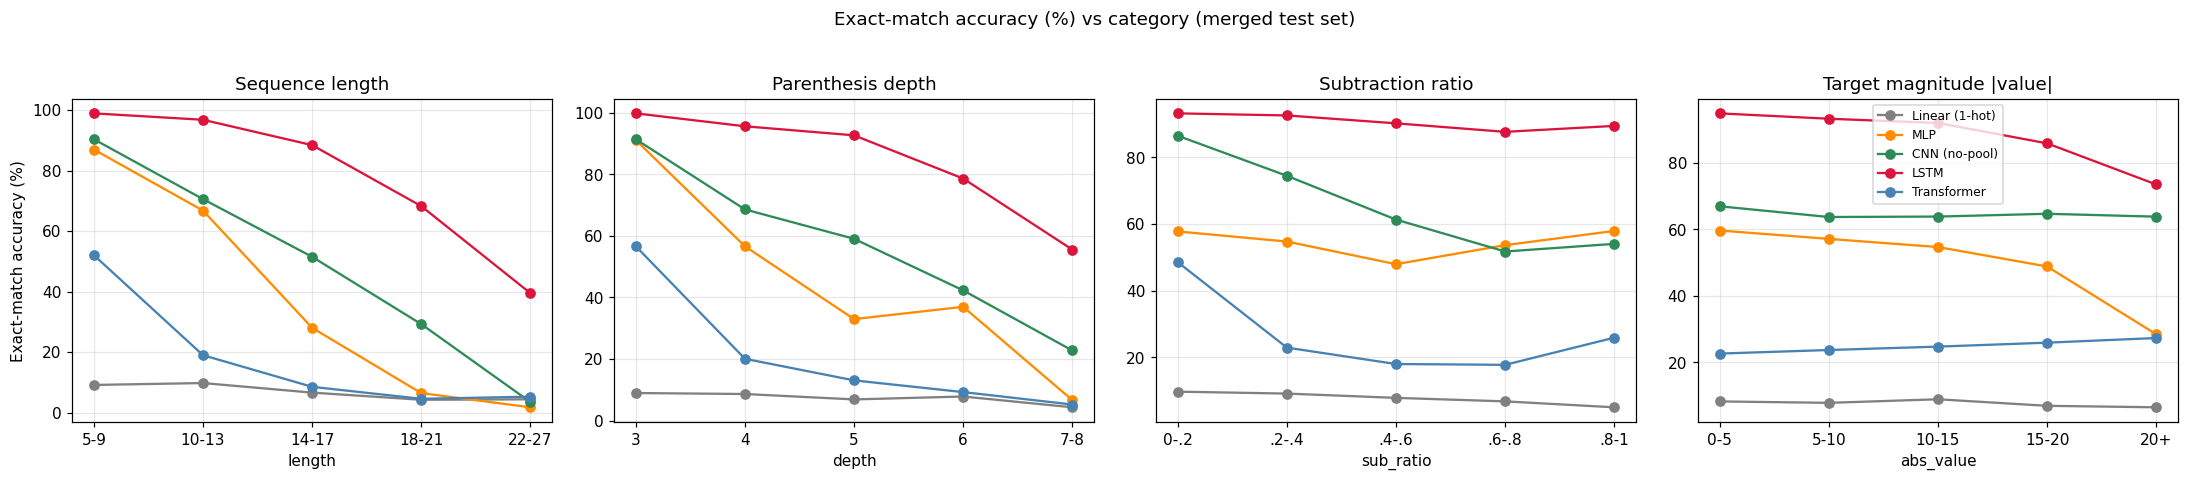

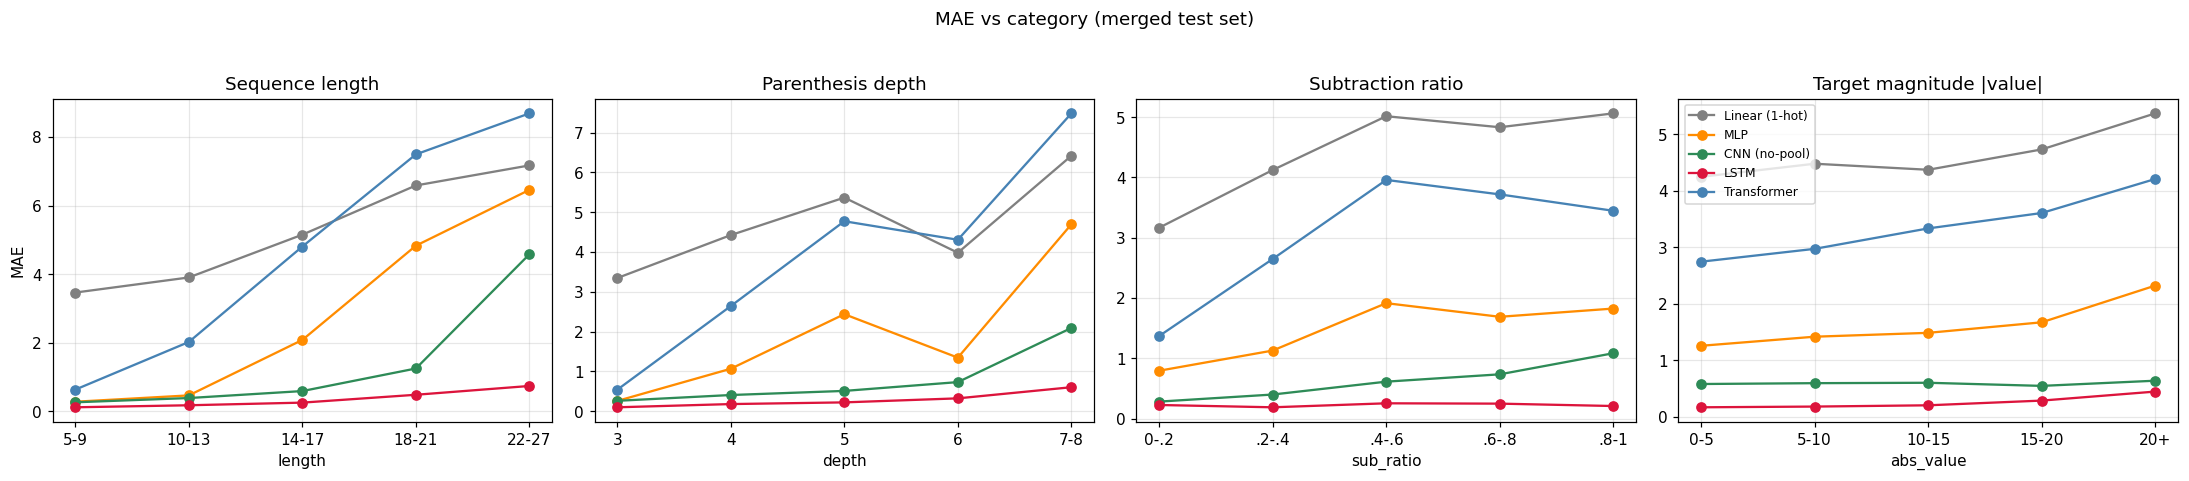

In [25]:
# ── Binned metrics + plots ───────────────────────────────────
def binned_metric(dim, bins, labels, metric='acc'):
    cats = pd.cut(test_all[dim], bins=bins, labels=labels, include_lowest=True)
    res = {}
    for name, p in preds.items():
        vals = []
        for lab in labels:
            m = (cats == lab).values
            if m.sum() == 0:
                vals.append(np.nan); continue
            if metric == 'acc':
                vals.append((p[m].round().astype(int) == y_true[m]).mean() * 100)
            else:
                vals.append(np.abs(p[m] - y_true[m]).mean())
        res[name] = vals
    return res

DIMS = [
    ('length',    [4, 9, 13, 17, 21, 27],          ['5-9','10-13','14-17','18-21','22-27']),
    ('depth',     [2, 3, 4, 5, 6, 8],              ['3','4','5','6','7-8']),
    ('sub_ratio', [-.01, .2, .4, .6, .8, 1.01],    ['0-.2','.2-.4','.4-.6','.6-.8','.8-1']),
    ('abs_value', [-.01, 5, 10, 15, 20, 60],       ['0-5','5-10','10-15','15-20','20+']),
]
MODEL_COLORS = {'Linear (1-hot)':'gray', 'MLP':'darkorange',
                'CNN (no-pool)':'seagreen', 'LSTM':'crimson', 'Transformer':'steelblue'}
TITLES = {'length':'Sequence length', 'depth':'Parenthesis depth',
          'sub_ratio':'Subtraction ratio', 'abs_value':'Target magnitude |value|'}

def plot_metric(metric, ylabel):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
    for ax, (dim, bins, labels) in zip(axes, DIMS):
        res = binned_metric(dim, bins, labels, metric=metric)
        for name, vals in res.items():
            ax.plot(labels, vals, marker='o', label=name, color=MODEL_COLORS[name])
        ax.set_title(TITLES[dim]); ax.set_xlabel(dim); ax.grid(alpha=0.3)
    axes[0].set_ylabel(ylabel)
    axes[-1].legend(fontsize=8)
    fig.suptitle(f'{ylabel} vs category (merged test set)', y=1.03, fontsize=12)
    plt.tight_layout(); plt.show()

plot_metric('acc', 'Exact-match accuracy (%)')
plot_metric('mae', 'MAE')


## Per-category analysis — interpretation

Overall exact-match on the merged test set (5500 ex.): **LSTM 90.5%, CNN no-pool 64.9%, MLP 53.3%, Transformer 24.2%, Linear 7.9%**. The breakdowns show *where* each model breaks:

- **vs depth** — the clearest separator. The LSTM declines gently (≈100% at depth 3 → ≈55% at depth 7–8), while the CNN (91%→22%) and MLP (91%→7%) fall steeply. Deep nesting is a recursive, long-range dependency: the recurrent state tracks it, but bounded-receptive-field / fixed-depth models cannot (parity ∉ AC⁰).
- **vs subtraction ratio** — the LSTM is essentially flat (~88–93% across all ratios), confirming it learns the sign-parity rule. The CNN degrades as subtraction dominates (86%→54%); the MLP is U-shaped (~48–58%, worst in the mixed .4–.6 band).
- **vs length** — only the LSTM degrades gracefully (99%→40%). The fixed-length models hit a truncation cliff at their max_len: the MLP (max 19) is already ~28% by 14–17 and ~2% at 22–27; the no-pool CNN (max 21) holds ~29% at 18–21 then collapses to ~5% at 22–27. The Transformer is weak at every length (≈52%→6%).
- **vs target magnitude** — accuracy falls as |value| grows. The LSTM stays highest but drops at |value|>20 (≈95%→73%); the MLP falls sharply there (≈60%→28%); the no-pool CNN is roughly flat (~65%); the Transformer flat and low (~25%).

**MAE corroborates, with one striking point:** on the hardest structural slices the Transformer's MAE is the *worst of all*, exceeding even the closed-form linear baseline — ≈8.7 at length 22–27 (Linear ≈7.2) and ≈7.4 at depth 7–8 (Linear ≈6.4). The undertrained Transformer makes large errors exactly where structure matters most.

These confirm the headline: the ranking tracks how well each architecture's inductive bias matches the recursive, position-sensitive structure of arithmetic.

# Appendix

Additional experiments outside the main narrative: a multi-scale CNN variant and an embedding-vs-nonlinearity ablation for the MLP.

### Multi-scale CNN variant (appendix)

An alternative CNN: three parallel branches (kernels 3/5/7) with masked **max + avg** pooling. The avg-pool restores the **count** signal that plain max-pool discards, so it reaches ~79% in-distribution (vs the max-only Basic CNN at ~44%). But its pooled features still lose **position**, so it trails the no-pool CNN on OOD (57.6 vs 67.0) and long (19.3 vs 42.3).

In [26]:
# ── Multi-scale CNN model (appendix) ────────────────────────────────────────────────
# Multi-scale parallel branches, 2 conv layers each (no padding).
#   k=3: RF=5 | k=5: RF=9 | k=7: RF=13
# Masked pooling: PAD tokens are right-padding only. A conv output
# position is "real" iff its whole receptive field lies within the
# expression. With 2 layers of kernel k the length shrinks by
# 2*(k-1), so per sample the number of valid output positions is
#   valid = real_len - 2*(k-1)
# We pool over ONLY those positions:
#   avg pool → masked_sum / valid   (divides by true length, not tensor length)
#   max pool → max over valid positions (PAD region set to -inf)
# This makes both pools invariant to how much PAD is appended, so
# training at max_len=21 and evaluating at max_len=27 give the same
# features for the same expression.

class MultiScaleCNN(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, embed_dim=32,
                 n_filters=64, kernels=(3, 5, 7)):
        super().__init__()
        self.kernels = kernels
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.convs = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(embed_dim,  n_filters, k), nn.ReLU(),
                nn.Conv1d(n_filters, n_filters, k), nn.ReLU(),
            )
            for k in kernels
        ])
        self.head = nn.Sequential(
            nn.Linear(2 * n_filters * len(kernels), 128),
            nn.ReLU(),
            nn.Linear(128, 1),
        )

    def forward(self, x):                           # x: (batch, seq_len)
        real_len = (x != PAD_IDX).sum(dim=1)        # (batch,) true length per sample
        e = self.embed(x).permute(0, 2, 1)          # (batch, embed_dim, seq_len)

        pooled = []
        for conv, k in zip(self.convs, self.kernels):
            out  = conv(e)                          # (batch, n_filters, Lout)
            Lout = out.size(-1)
            reduction = 2 * (k - 1)                 # 2 conv layers shrink by this
            valid = (real_len - reduction).clamp(min=1)          # (batch,)

            pos  = torch.arange(Lout, device=x.device)           # (Lout,)
            mask = pos[None, :] < valid[:, None]                 # (batch, Lout) True=real
            mask = mask.unsqueeze(1)                             # (batch, 1, Lout)

            # masked avg: sum over real positions / true length
            avg = (out * mask).sum(dim=-1) / valid.unsqueeze(1).float()
            # masked max: set PAD positions to -inf so they never win
            mx  = out.masked_fill(~mask, float("-inf")).max(dim=-1).values

            pooled.append(mx)
            pooled.append(avg)

        return self.head(torch.cat(pooled, dim=1))  # (batch, 1)


In [27]:
# ── Train Multi-scale CNN (appendix) ─────────────────────────
cnn_multiscale = MultiScaleCNN().to(device)
def _train_ms():
    opt  = torch.optim.Adam(cnn_multiscale.parameters(), lr=3e-4)
    crit = nn.MSELoss()
    for epoch in range(1, 51):
        cnn_multiscale.train(); total = 0.0
        for X, y in aug_loaders['train']:
            X, y = X.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(cnn_multiscale(X).squeeze(-1), y)
            loss.backward(); opt.step(); total += loss.item()
        if epoch % 10 == 0:
            val_acc, val_mae, _ = evaluate(cnn_multiscale, aug_loaders['validation'])
            print(f"Epoch {epoch:3d}  loss={total/len(aug_loaders['train']):.4f}"
                  f"  val_acc={val_acc:.2f}%  val_MAE={val_mae:.3f}")
fit_or_load(cnn_multiscale, 'cnn_multiscale', _train_ms)
cnn_eval_loaders = make_loaders(splits, EVAL_MAX_LEN)
eval_all(cnn_multiscale, cnn_eval_loaders, 'Multi-Scale CNN — Final Results (eval max_len=27)')


Epoch  10  loss=2.3447  val_acc=50.35%  val_MAE=0.751
Epoch  20  loss=0.8159  val_acc=67.45%  val_MAE=0.510
Epoch  30  loss=0.4739  val_acc=68.80%  val_MAE=0.494
Epoch  40  loss=0.3407  val_acc=76.65%  val_MAE=0.404
Epoch  50  loss=0.3020  val_acc=79.90%  val_MAE=0.358
[train] cnn_multiscale

Multi-Scale CNN — Final Results (eval max_len=27)
split         exact_acc      MAE     RMSE
--------------------------------------------
train            88.60%    0.244    0.343
validation       79.90%    0.358    0.677
test_id          79.05%    0.378    0.725
test_ood         57.55%    0.948    1.975
test_long        19.33%    2.870    4.896


### Multi-scale CNN — commentary

**Architecture** — three parallel `Conv1d` branches (kernels 3/5/7, 2 conv layers each, 64 filters), masked **max + avg** pooling per branch (length-invariant), 384-dim concat → 2-layer FC head.

**Result** — val 79.9 / test_id 79.1 / test_ood 57.6 / test_long 19.3. The avg-pool branch recovers the count information that max-only pooling throws away, lifting it from the Basic CNN's ~44% to ~79% in-distribution. But pooling still discards absolute position, so it generalizes worse than the no-pool CNN on deeper (OOD) and longer inputs.

**Why multi-scale kernels** — arithmetic has structure at multiple granularities: a single operator acts on neighbours (k=3), a parenthesised pair spans 5–7 chars (k=5/7).

### CNN vs MLP — expressivity (subset) vs inductive bias

**Is the CNN a subset of the MLP?** In expressivity, essentially yes: a `Conv1d` is a fully-connected layer with two constraints — locality (weights outside the k-window forced to 0) and weight sharing (same kernel at every position). So {conv functions} ⊂ {FC functions}, and a wide-enough MLP could represent any function the no-pool CNN computes.

**Why the CNN still generalizes better:** expressivity ≠ what is learned from finite data. Weight sharing lets the conv learn a local pattern once and reuse it everywhere; the MLP relearns it per position. The controlled comparison (same augmented data, max_len=21) confirms it:

| same data, max_len 21 | test_id | test_ood |
|---|---|---|
| MLP (aug) | 63.7 | 43.4 |
| CNN no-pool (aug) | 79.8 | 67.0 |

The conv front-end adds +16pp test_id and +24pp test_ood over the MLP on identical data — an inductive-bias (generalization) gain, not a capacity gain.

**Note:** the MLP on augmented data (63.7) is actually *worse* in-distribution than the MLP on raw data (77.6) — the more varied augmented shapes dilute the position-specific patterns the MLP relies on, another sign of its weak generalization.

In [28]:
# ── Clean comparison: MLP trained on the SAME augmented data ──
# Matches the no-pool CNN's data (aug, max_len=21) to isolate
# architecture (inductive bias) from the data-augmentation effect.
mlp_aug = MLP(max_len=AUG_MAX_LEN).to(device)
fit_or_load(mlp_aug, 'mlp_aug',
            lambda: train_model(mlp_aug, aug_loaders, epochs=30, lr=1e-3))
eval_all(mlp_aug, make_loaders(splits, AUG_MAX_LEN),
         'MLP on augmented data (max_len=21) — vs cnn_nopool')


[train] mlp_aug

MLP on augmented data (max_len=21) — vs cnn_nopool
split         exact_acc      MAE     RMSE
--------------------------------------------
train            70.82%    0.405    0.539
validation       63.75%    0.522    0.756
test_id          63.65%    0.540    0.812
test_ood         43.40%    1.175    2.134
test_long        14.87%    3.029    4.374


## Ablation — Embedding vs Non-linearity
Two additional conditions to isolate whether the MLP gain comes from
the learned embedding or from the non-linear activation layers.

| Condition | Encoding | Layers | Cell |
|---|---|---|---|
| A | one-hot (fixed) | Linear only | Cell 12 |
| B | Embedding (learned) | Linear only | below |
| C | one-hot (fixed) | MLP + ReLU | below |
| D | Embedding (learned) | MLP + ReLU | Cell 16 |


In [29]:
import torch.nn.functional as F

# ── Condition B: Embedding + Linear (no hidden layers) ────────
class EmbedLinear(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, embed_dim=32, max_len=TRAIN_MAX_LEN):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.linear = nn.Linear(max_len * embed_dim, 1)

    def forward(self, x):
        return self.linear(self.embed(x).flatten(1))

# ── Condition C: one-hot + MLP with ReLU (no learned embedding) ──
class OneHotMLP(nn.Module):
    def __init__(self, vocab_size=VOCAB_SIZE, max_len=TRAIN_MAX_LEN, hidden=256):
        super().__init__()
        self.vocab_size = vocab_size
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(max_len * vocab_size, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden // 2),           nn.ReLU(),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, x):
        oh = F.one_hot(x, self.vocab_size).float()  # (batch, max_len, vocab_size)
        return self.net(oh)


In [30]:
# train_model is defined in the shared-infrastructure cell
embed_linear = EmbedLinear().to(device)
onehot_mlp   = OneHotMLP().to(device)
fit_or_load(embed_linear, 'embed_linear', lambda: train_model(embed_linear, mlp_loaders))
fit_or_load(onehot_mlp,   'onehot_mlp',   lambda: train_model(onehot_mlp,   mlp_loaders))

# ── Comparison table ──────────────────────────────────────────
conditions = {
    "A  one-hot + Linear   (cell 12)": None,   # sklearn — re-evaluate below
    "B  Embed   + Linear   (ablation)": embed_linear,
    "C  one-hot + MLP+ReLU (ablation)": onehot_mlp,
    "D  Embed   + MLP+ReLU (cell 16) ": mlp,
}

# Re-evaluate condition A with sklearn (already trained as lr / lr_oh earlier)
from sklearn.metrics import mean_absolute_error, mean_squared_error as mse_fn
def sklearn_metrics(model_sk, encode_fn):
    rows = {}
    for name, df in splits.items():
        X = encode_fn(df); y = df["value"].values
        pred = model_sk.predict(X); pi = pred.round().astype(int)
        rows[name] = ((pi==y).mean()*100, mean_absolute_error(y,pred), mse_fn(y,pred)**.5)
    return rows

cond_A = sklearn_metrics(lr_oh, onehot_encode)

print()
header = f"{'condition':<35}" + "".join(f"  {s:<10}" for s in splits)
print(header)
print(f"{'':35}" + "  exact_acc  " * len(splits))
print("-" * (35 + 13 * len(splits)))

for label, model in conditions.items():
    row = cond_A if model is None else {}
    if model is not None:
        for name, loader in mlp_loaders.items():
            acc, mae, rmse = evaluate(model, loader)
            row[name] = (acc, mae, rmse)
    accs = "  ".join(f"{row[n][0]:>8.1f}%" for n in splits)
    print(f"{label:<35}  {accs}")

print()
print("MAE:")
for label, model in conditions.items():
    row = cond_A if model is None else {}
    if model is not None:
        for name, loader in mlp_loaders.items():
            acc, mae, rmse = evaluate(model, loader)
            row[name] = (acc, mae, rmse)
    maes = "  ".join(f"{row[n][1]:>9.3f}" for n in splits)
    print(f"{label:<35}  {maes}")


[train] embed_linear
[train] onehot_mlp

condition                            train       validation  test_id     test_ood    test_long 
                                     exact_acc    exact_acc    exact_acc    exact_acc    exact_acc  
----------------------------------------------------------------------------------------------------
A  one-hot + Linear   (cell 12)           9.7%       8.8%       9.3%       8.8%       4.9%
B  Embed   + Linear   (ablation)          9.4%       8.8%       8.8%       8.6%       5.9%
C  one-hot + MLP+ReLU (ablation)         79.2%      68.8%      67.9%      50.3%      13.7%
D  Embed   + MLP+ReLU (cell 16)          85.0%      77.5%      77.6%      56.8%      16.3%

MAE:
A  one-hot + Linear   (cell 12)          3.592      3.615      3.616      4.271      6.030
B  Embed   + Linear   (ablation)         3.595      3.616      3.616      4.178      5.667
C  one-hot + MLP+ReLU (ablation)         0.336      0.470      0.477      1.296      4.035
D  Embed   + MLP+R

In [31]:
# ── Save all trained weights into ONE file ───────────────────
# Saves only when models were trained THIS session (not loaded from
# a downloaded file). Then upload model_weights.pt to Drive + set CKPT_FILE_ID.
import os
if CKPT and not CKPT_LOADED:
    torch.save(CKPT, "model_weights.pt")
    p  = os.path.abspath("model_weights.pt")
    mb = os.path.getsize(p) / 1e6
    print(f"Saved {len(CKPT)} models -> {p}  ({mb:.1f} MB)")
    print("Models:", list(CKPT))
    print("Next: upload this file to Google Drive, share it, paste its ID into CKPT_FILE_ID.")
elif CKPT_LOADED:
    print("Weights were loaded from model_weights.pt -> nothing to re-save.")
else:
    print("CKPT is empty -> nothing to save.")


load_pretrained=True -> used downloaded weights; nothing to save.
